# 03 · Exploratory Data Analysis

**Purpose:** explore sentiment, complaint categories, retweets and time patterns in the cleaned dataset.

**Questions answered**
- How negative is airline feedback on Twitter overall, and how does each airline compare?
- Which complaint categories dominate, and does the mix differ by airline?
- Do complaints get amplified (retweeted) more than praise?
- What do the date, weekday and hour patterns show, and what do they *not* show?

Each analysis follows the same pattern: **Objective → Code → Output / Chart → Insight**.

> **Project KPI: Net Sentiment Score = Positive % − Negative %**
> A project-defined KPI for comparing airlines (not an official industry metric). It ranges from −100 (all negative) to +100 (all positive).

> **Airline labels:** the source labelled JetBlue tweets as "Delta". Notebook 02 corrects this with a documented rule, so this notebook reports **JetBlue**.

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Make the project's src/ package importable from any folder inside the repository
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from src.config import SENTIMENT_ORDER
from src.data import load_clean_tweets
from src.plotting import CATEGORICAL_COLORS, PRIMARY_COLOR, SENTIMENT_COLORS, apply_style, save_figure
from src.preprocessing import mask_user_handles

pd.set_option("display.max_colwidth", 140)
apply_style()

WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
SENTIMENT_PALETTE = [SENTIMENT_COLORS[s] for s in SENTIMENT_ORDER]


def show_tweets(frame):
    """Display a table of tweets with non-airline @usernames masked."""
    return frame.assign(text=frame["text"].map(mask_user_handles))

In [2]:
df = load_clean_tweets(parse_dates=True)

# Subset used by every complaint analysis
negative_df = df[df["airline_sentiment"] == "Negative"].copy()

print(f"Cleaned dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Negative tweets: {len(negative_df):,}")

Cleaned dataset: 14,481 rows x 23 columns
Negative tweets: 9,082


## 1. Overall Sentiment Distribution
**Objective:** measure how many tweets fall into each sentiment category.

,tweets
airline_sentiment,
Positive,2332
Neutral,3067
Negative,9082


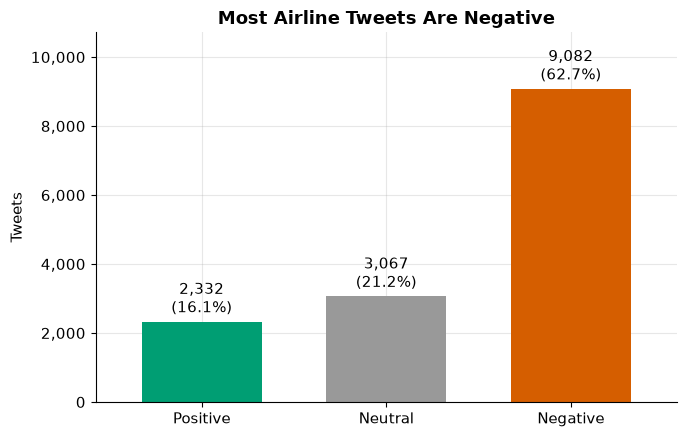

In [3]:
sentiment_counts = df["airline_sentiment"].value_counts().reindex(SENTIMENT_ORDER)
display(sentiment_counts.to_frame("tweets"))

fig, ax = plt.subplots(figsize=(7, 4.5))
sentiment_counts.plot(kind="bar", color=SENTIMENT_PALETTE, ax=ax, width=0.65)
ax.set_title("Most Airline Tweets Are Negative")
ax.set_xlabel("")
ax.set_ylabel("Tweets")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.tick_params(axis="x", rotation=0)
ax.bar_label(ax.containers[0], labels=[f"{n:,}\n({n / len(df):.1%})" for n in sentiment_counts], padding=3)
ax.set_ylim(0, sentiment_counts.max() * 1.18)
plt.tight_layout()
save_figure("sentiment_distribution.png")
plt.show()

**Insight:** Negative is the largest category by a wide margin (9,082 tweets), more than the Neutral and Positive categories combined (5,399).

## 2. Sentiment Percentages
**Objective:** express the sentiment mix as a share of all tweets.

In [4]:
sentiment_pct = (df["airline_sentiment"].value_counts(normalize=True) * 100).reindex(SENTIMENT_ORDER)
display(sentiment_pct.round(2).to_frame("percentage"))

overall_net_score = sentiment_pct["Positive"] - sentiment_pct["Negative"]
print(f"Overall Net Sentiment Score: {overall_net_score:.2f}")

,percentage
airline_sentiment,
Positive,16.10
Neutral,21.18
Negative,62.72


Overall Net Sentiment Score: -46.61


**Insight:** 62.72% of tweets are Negative, 21.18% Neutral and 16.10% Positive, giving an overall Net Sentiment Score of −46.61. Customers mostly tag airlines on Twitter to complain or ask for help, so the negative skew describes this channel, not overall customer satisfaction.

## 3. Tweet Volume by Airline
**Objective:** see which airlines receive the most discussion.

,tweets,share_pct
airline,,
United,3822,26.39
US Airways,2913,20.12
American,2604,17.98
Southwest,2420,16.71
JetBlue,2218,15.32
Virgin America,504,3.48


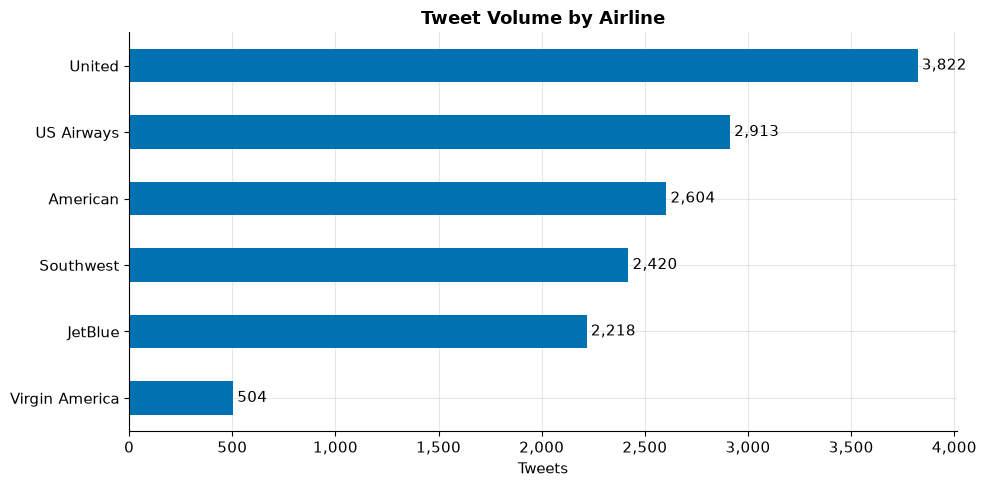

In [5]:
airline_volume = df["airline"].value_counts()
airline_share = (airline_volume / len(df) * 100).round(2)
display(pd.DataFrame({"tweets": airline_volume, "share_pct": airline_share}))

ax = airline_volume.sort_values().plot(kind="barh", color=PRIMARY_COLOR)
ax.set_title("Tweet Volume by Airline")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("Tweets")
ax.set_ylabel("")
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)
plt.tight_layout()
plt.show()

**Insight:** United has the most tweets (3,822; 26.39% of the dataset) and Virgin America the fewest (504; 3.48%). Volume differs by roughly 7.6×, so raw counts favour the large carriers. Later comparisons use within-airline percentages.

## 4. Sentiment Counts by Airline
**Objective:** compare the absolute number of Positive, Neutral and Negative tweets per airline.

airline_sentiment,Positive,Neutral,Negative
airline,,,
United,492,697,2633
US Airways,269,381,2263
American,306,432,1866
Southwest,570,664,1186
JetBlue,543,722,953
Virgin America,152,171,181


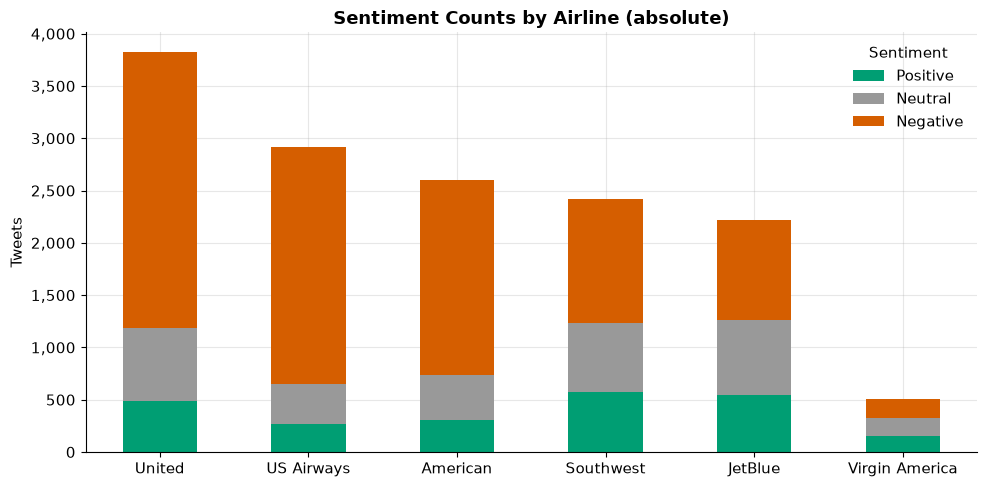

In [6]:
sentiment_by_airline = (
    pd.crosstab(df["airline"], df["airline_sentiment"])
    .reindex(columns=SENTIMENT_ORDER)
    .loc[airline_volume.index]            # order airlines by total volume
)
display(sentiment_by_airline)

ax = sentiment_by_airline.plot(kind="bar", stacked=True, color=SENTIMENT_PALETTE)
ax.set_title("Sentiment Counts by Airline (absolute)")
ax.set_xlabel("")
ax.set_ylabel("Tweets")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Sentiment")
plt.tight_layout()
plt.show()

**Insight:** United, US Airways and American each have more than 1,800 Negative tweets, far above the other three carriers. This view mixes volume with sentiment, so the next section normalises it.

## 5. Sentiment Percentages by Airline
**Objective:** compare each airline's sentiment mix fairly, whatever its volume.

airline_sentiment,Positive,Neutral,Negative
airline,,,
Virgin America,30.16,33.93,35.91
JetBlue,24.48,32.55,42.97
Southwest,23.55,27.44,49.01
United,12.87,18.24,68.89
American,11.75,16.59,71.66
US Airways,9.23,13.08,77.69


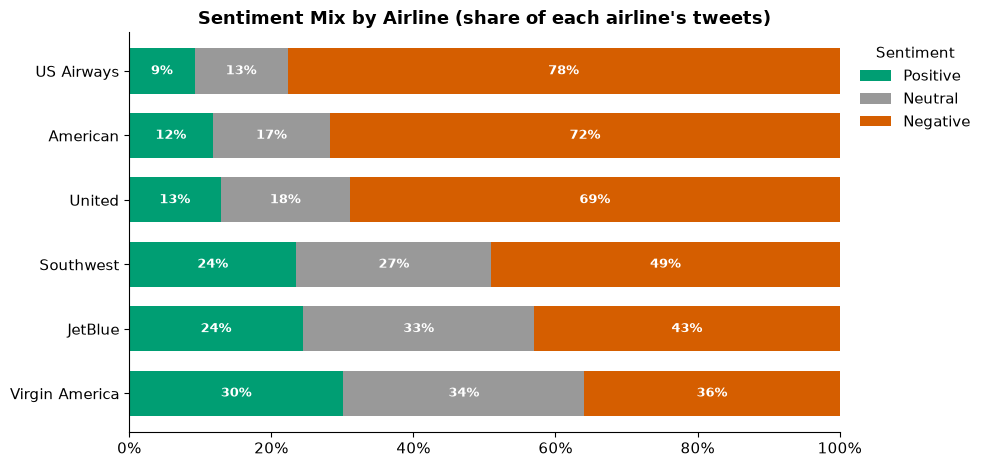

In [7]:
sentiment_pct_by_airline = sentiment_by_airline.div(sentiment_by_airline.sum(axis=1), axis=0) * 100
sentiment_pct_by_airline = sentiment_pct_by_airline.sort_values("Negative")
display(sentiment_pct_by_airline.round(2))

fig, ax = plt.subplots(figsize=(10, 4.8))
sentiment_pct_by_airline.plot(kind="barh", stacked=True, color=SENTIMENT_PALETTE, width=0.7, ax=ax)
for container, sentiment in zip(ax.containers, SENTIMENT_ORDER):
    ax.bar_label(container, fmt="%.0f%%", label_type="center", color="white", fontsize=9, fontweight="bold")
ax.set_title("Sentiment Mix by Airline (share of each airline's tweets)")
ax.set_xlabel("")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlim(0, 100)
ax.legend(title="Sentiment", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(False)
plt.tight_layout()
save_figure("sentiment_mix_by_airline.png")
plt.show()

**Insight:** Two groups stand out. Virgin America, JetBlue and Southwest have Negative shares below 50%. US Airways, American and United have Negative shares between about 69% and 78%.

## 6. Airline with the Highest Positive Sentiment %
**Objective:** rank airlines by Positive share.

In [8]:
positive_ranking = sentiment_pct_by_airline["Positive"].sort_values(ascending=False)
display(positive_ranking.round(2).to_frame("positive_pct"))
print(f"Highest Positive %: {positive_ranking.index[0]} ({positive_ranking.iloc[0]:.2f}%)")
print(f"Lowest Positive %:  {positive_ranking.index[-1]} ({positive_ranking.iloc[-1]:.2f}%)")

,positive_pct
airline,
Virgin America,30.16
JetBlue,24.48
Southwest,23.55
United,12.87
American,11.75
US Airways,9.23


Highest Positive %: Virgin America (30.16%)
Lowest Positive %:  US Airways (9.23%)


**Insight:** Virgin America has the highest Positive share (30.16%), more than three times that of US Airways (9.23%). Virgin America also has the smallest sample (504 tweets), so its percentages are less certain. Notebook 05 quantifies this with confidence intervals.

## 7. Airline with the Highest Negative Sentiment %
**Objective:** rank airlines by Negative share.

In [9]:
negative_ranking = sentiment_pct_by_airline["Negative"].sort_values(ascending=False)
display(negative_ranking.round(2).to_frame("negative_pct"))
print(f"Highest Negative %: {negative_ranking.index[0]} ({negative_ranking.iloc[0]:.2f}%)")

,negative_pct
airline,
US Airways,77.69
American,71.66
United,68.89
Southwest,49.01
JetBlue,42.97
Virgin America,35.91


Highest Negative %: US Airways (77.69%)


**Insight:** US Airways has the highest Negative share (77.69%), followed by American (71.66%) and United (68.89%). Roughly 7 in 10 tweets or more about these three carriers are negative.

## 8. Net Sentiment Score by Airline
**Objective:** combine the Positive and Negative shares into the project KPI (Positive % − Negative %).

,net_sentiment_score
airline,
US Airways,-68.45
American,-59.91
United,-56.02
Southwest,-25.45
JetBlue,-18.49
Virgin America,-5.75


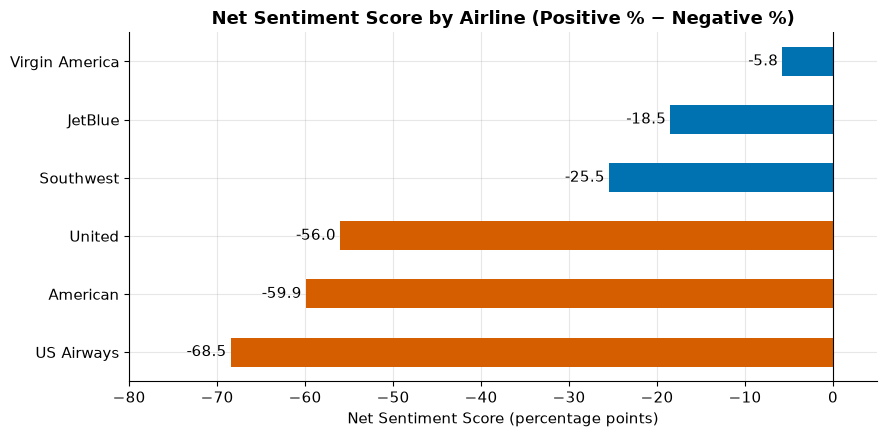

In [10]:
net_sentiment = (sentiment_pct_by_airline["Positive"] - sentiment_pct_by_airline["Negative"]).sort_values()
display(net_sentiment.round(2).to_frame("net_sentiment_score"))

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = [SENTIMENT_COLORS["Negative"] if score < -50 else PRIMARY_COLOR for score in net_sentiment]
net_sentiment.plot(kind="barh", color=colors, ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Net Sentiment Score by Airline (Positive % − Negative %)")
ax.set_xlabel("Net Sentiment Score (percentage points)")
ax.set_ylabel("")
ax.set_xlim(-80, 5)
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
plt.tight_layout()
save_figure("net_sentiment_score.png")
plt.show()

**Insight:** Every airline has a negative Net Sentiment Score, which is expected for a complaint-heavy channel. Virgin America is closest to zero (−5.75) and US Airways is lowest (−68.45). The gap between the best and worst airline is about 63 points.

## 9. Negative-Reason Distribution
**Objective:** find the most common complaint categories among Negative tweets.

,negative_tweets,share_pct
negativereason,,
Customer Service Issue,2883,31.74
Late Flight,1652,18.19
Can't Tell,1182,13.01
Cancelled Flight,831,9.15
Lost Luggage,718,7.91
Bad Flight,573,6.31
Flight Booking Problems,520,5.73
Flight Attendant Complaints,474,5.22
Long Lines,175,1.93


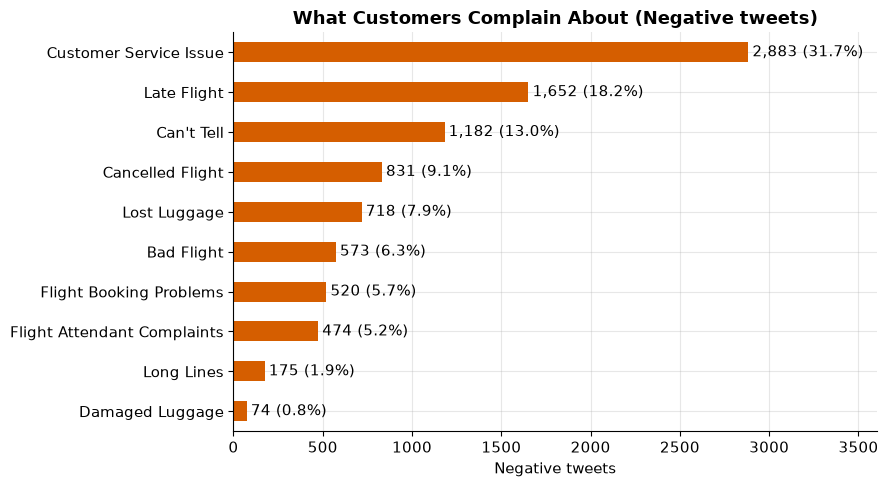

In [11]:
reason_counts = negative_df["negativereason"].value_counts()
reason_pct = (reason_counts / reason_counts.sum() * 100).round(2)
display(pd.DataFrame({"negative_tweets": reason_counts, "share_pct": reason_pct}))

fig, ax = plt.subplots(figsize=(9, 5))
reason_counts.sort_values().plot(kind="barh", color=SENTIMENT_COLORS["Negative"], ax=ax)
ax.set_title("What Customers Complain About (Negative tweets)")
ax.set_xlabel("Negative tweets")
ax.set_ylabel("")
ax.bar_label(ax.containers[0], labels=[f"{n:,} ({n / reason_counts.sum():.1%})" for n in reason_counts.sort_values()], padding=3)
ax.set_xlim(0, reason_counts.max() * 1.25)
plt.tight_layout()
save_figure("complaint_categories.png")
plt.show()

**Insight:** Customer Service Issue is the leading complaint (2,883 tweets; 31.74% of Negative tweets), followed by Late Flight (18.19%). "Can't Tell" is the third-largest bucket (13.01%), so about one in eight complaints has no identifiable category.

## 10. Negative Reasons by Airline
**Objective:** compare complaint mix across airlines. Each airline's complaints are shown as a percentage of its own Negative tweets, so airlines of different sizes can be compared.

In [12]:
reason_by_airline = pd.crosstab(negative_df["airline"], negative_df["negativereason"])
display(reason_by_airline)

negativereason,Bad Flight,Can't Tell,Cancelled Flight,Customer Service Issue,Damaged Luggage,Flight Attendant Complaints,Flight Booking Problems,Late Flight,Long Lines,Lost Luggage
airline,,,,,,,,,,
American,80,191,230,741,12,80,121,236,32,143
JetBlue,64,185,51,199,11,60,44,269,13,57
Southwest,90,159,162,391,14,38,61,152,29,90
US Airways,104,246,189,811,11,123,122,453,50,154
United,216,379,181,681,22,168,144,525,48,269
Virgin America,19,22,18,60,4,5,28,17,3,5


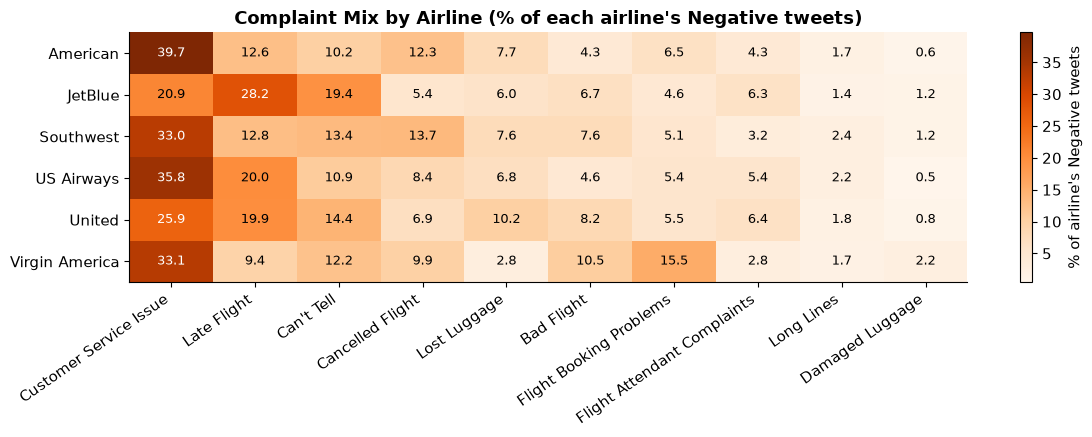

In [13]:
# Share of each airline's Negative tweets (rows sum to 100%)
reason_share_by_airline = reason_by_airline.div(reason_by_airline.sum(axis=1), axis=0) * 100
reason_share_by_airline = reason_share_by_airline[reason_counts.index]   # overall-rank column order

fig, ax = plt.subplots(figsize=(12, 4.5))
heatmap = ax.imshow(reason_share_by_airline.values, cmap="Oranges", aspect="auto")
ax.set_xticks(range(len(reason_share_by_airline.columns)))
ax.set_xticklabels(reason_share_by_airline.columns, rotation=35, ha="right")
ax.set_yticks(range(len(reason_share_by_airline.index)))
ax.set_yticklabels(reason_share_by_airline.index)
ax.grid(False)
for row in range(reason_share_by_airline.shape[0]):
    for col in range(reason_share_by_airline.shape[1]):
        value = reason_share_by_airline.iat[row, col]
        ax.text(col, row, f"{value:.1f}", ha="center", va="center",
                color="white" if value > 25 else "black", fontsize=9)
ax.set_title("Complaint Mix by Airline (% of each airline's Negative tweets)")
fig.colorbar(heatmap, ax=ax, label="% of airline's Negative tweets")
plt.tight_layout()
save_figure("complaint_mix_heatmap.png")
plt.show()

**Insight:** Complaint profiles differ. Customer Service Issue makes up 39.7% of American's and 35.8% of US Airways' Negative tweets but only 20.9% of JetBlue's. JetBlue's largest share is Late Flight (28.2%). Virgin America has a relatively high Flight Booking Problems share (15.5%), and United has the highest Lost Luggage share (10.2%).

## 11. Most Common Complaint for Each Airline
**Objective:** identify each airline's top complaint category.

In [14]:
top_complaint_per_airline = pd.DataFrame({
    "top_complaint": reason_by_airline.idxmax(axis=1),
    "complaint_tweets": reason_by_airline.max(axis=1),
    "share_of_airline_negative_pct": (reason_share_by_airline.max(axis=1)).round(2),
}).sort_values("complaint_tweets", ascending=False)

top_complaint_per_airline

,top_complaint,complaint_tweets,share_of_airline_negative_pct
airline,,,
US Airways,Customer Service Issue,811,35.84
American,Customer Service Issue,741,39.71
United,Customer Service Issue,681,25.86
Southwest,Customer Service Issue,391,32.97
JetBlue,Late Flight,269,28.23
Virgin America,Customer Service Issue,60,33.15


**Insight:** Customer Service Issue is the top complaint for five of six airlines. JetBlue is the exception, where Late Flight leads.

## 12. Retweet Distribution
**Objective:** understand how retweets are distributed before comparing averages.

In [15]:
retweet_stats = df["retweet_count"].describe()
display(retweet_stats.to_frame("retweet_count"))

zero_share = (df["retweet_count"] == 0).mean() * 100
print(f"Tweets with 0 retweets: {zero_share:.2f}%")
print(f"Tweets with 1+ retweets: {(df['retweet_count'] > 0).sum():,}")
print(f"Total retweets: {df['retweet_count'].sum():,}")

,retweet_count
count,14481.000000
mean,0.083143
std,0.749304
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,44.000000


Tweets with 0 retweets: 94.73%
Tweets with 1+ retweets: 763
Total retweets: 1,204


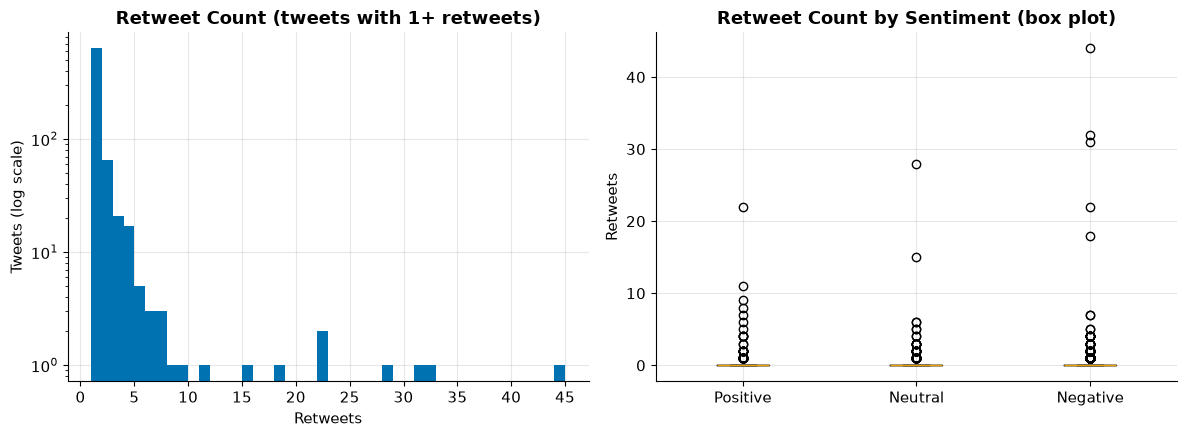

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: histogram of retweeted tweets only (log scale, because zeros dominate)
retweeted = df.loc[df["retweet_count"] > 0, "retweet_count"]
axes[0].hist(retweeted, bins=range(1, retweeted.max() + 2), color=PRIMARY_COLOR)
axes[0].xaxis.set_major_locator(mtick.MaxNLocator(integer=True))
axes[0].set_yscale("log")
axes[0].set_title("Retweet Count (tweets with 1+ retweets)")
axes[0].set_xlabel("Retweets")
axes[0].set_ylabel("Tweets (log scale)")

# Right: box plot by sentiment shows outliers clearly
axes[1].boxplot(
    [df.loc[df["airline_sentiment"] == s, "retweet_count"] for s in SENTIMENT_ORDER],
    tick_labels=SENTIMENT_ORDER,
)
axes[1].set_title("Retweet Count by Sentiment (box plot)")
axes[1].set_ylabel("Retweets")

plt.tight_layout()
plt.show()

**Insight:** 94.73% of tweets have zero retweets and the median is 0. A handful of tweets reach 20–44 retweets, so averages are driven by a few outliers and should be read alongside the share of tweets retweeted.

## 13. Average Retweets by Sentiment
**Objective:** compare amplification across sentiment categories.

,tweets,total_retweets,average_retweets,median_retweets,pct_retweeted
airline_sentiment,,,,,
Positive,2332,161,0.0690,0.0,3.2161
Neutral,3067,188,0.0613,0.0,3.0323
Negative,9082,855,0.0941,0.0,6.5514


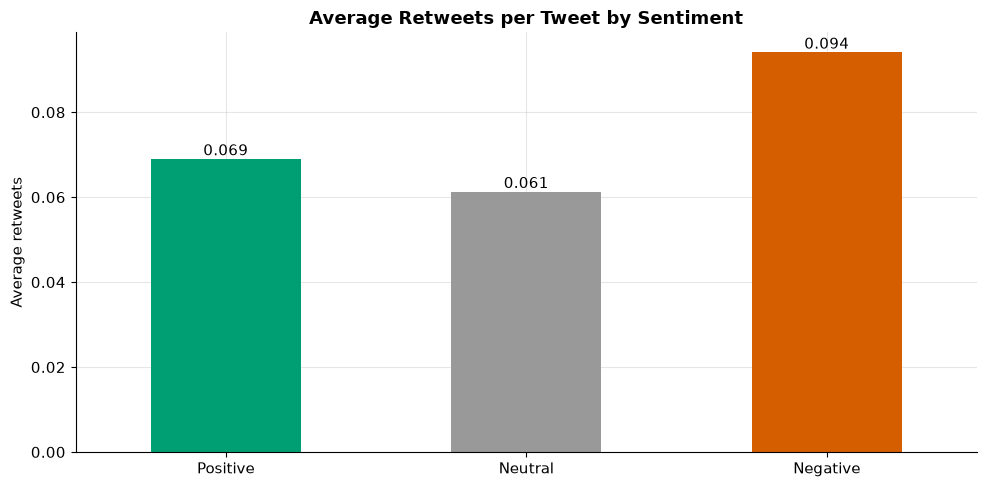

In [17]:
retweets_by_sentiment = (
    df.groupby("airline_sentiment")["retweet_count"]
    .agg(tweets="count", total_retweets="sum", average_retweets="mean", median_retweets="median")
    .assign(pct_retweeted=df.groupby("airline_sentiment")["retweet_count"].apply(lambda s: (s > 0).mean() * 100))
    .reindex(SENTIMENT_ORDER)
    .round(4)
)
display(retweets_by_sentiment)

ax = retweets_by_sentiment["average_retweets"].plot(kind="bar", color=SENTIMENT_PALETTE)
ax.set_title("Average Retweets per Tweet by Sentiment")
ax.set_xlabel("")
ax.set_ylabel("Average retweets")
ax.tick_params(axis="x", rotation=0)
ax.bar_label(ax.containers[0], fmt="{:.3f}")
plt.tight_layout()
plt.show()

**Insight:** Negative tweets have the highest average retweets (0.094) and are about twice as likely to be retweeted at all (6.55% vs about 3% for Positive and Neutral). In this sample, complaints spread slightly further than praise.

## 14. Average Retweets by Airline
**Objective:** compare retweet activity across airlines.

In [18]:
retweets_by_airline = (
    df.groupby("airline")["retweet_count"]
    .agg(tweets="count", total_retweets="sum", average_retweets="mean", max_retweets="max")
    .assign(pct_retweeted=df.groupby("airline")["retweet_count"].apply(lambda s: (s > 0).mean() * 100))
    .sort_values("average_retweets", ascending=False)
    .round(4)
)
retweets_by_airline

,tweets,total_retweets,average_retweets,max_retweets,pct_retweeted
airline,,,,,
JetBlue,2218,248,0.1118,31,4.0577
United,3822,421,0.1102,7,9.9163
US Airways,2913,249,0.0855,44,4.0851
Southwest,2420,145,0.0599,22,3.5537
Virgin America,504,26,0.0516,4,2.9762
American,2604,115,0.0442,5,2.8418


**Data-quality check:** several of JetBlue's most-retweeted tweets (next section) are reactions to a JetBlue marketing post containing the phrase "on fleek". The cell below uses a plain text filter to measure how much that one post inflates JetBlue's average.

In [19]:
jetblue_df = df[df["airline"] == "JetBlue"]
is_fleek_reaction = jetblue_df["text"].str.contains("fleek", case=False)

print(f"JetBlue tweets reacting to the 'on fleek' post: {is_fleek_reaction.sum():,} of {len(jetblue_df):,}")
print(f"Retweets on those tweets: {jetblue_df.loc[is_fleek_reaction, 'retweet_count'].sum():,} "
      f"of JetBlue's {jetblue_df['retweet_count'].sum():,}")
print(f"JetBlue average retweets (all rows): {jetblue_df['retweet_count'].mean():.4f}")
print(f"JetBlue average retweets (excluding 'on fleek' reactions): {jetblue_df.loc[~is_fleek_reaction, 'retweet_count'].mean():.4f}")

JetBlue tweets reacting to the 'on fleek' post: 150 of 2,218
Retweets on those tweets: 132 of JetBlue's 248
JetBlue average retweets (all rows): 0.1118
JetBlue average retweets (excluding 'on fleek' reactions): 0.0561


**Insight:** JetBlue (0.112) and United (0.110) have the highest average retweets. United's figure is broad-based: it has the highest share of tweets retweeted at least once (9.92%). JetBlue's figure comes mostly from one viral post: 150 reactions to it carry 132 of JetBlue's 248 retweets. Excluding them lowers JetBlue's average to 0.056, below United, US Airways and Southwest. Average retweets are therefore a fragile metric for comparing airlines here.

## 15. Most-Retweeted Tweets
**Objective:** inspect the tweets with the highest retweet counts.

In [20]:
most_retweeted = df.nlargest(10, "retweet_count")[
    ["tweet_id", "airline", "airline_sentiment", "negativereason", "retweet_count", "text"]
]
show_tweets(most_retweeted)

,tweet_id,airline,airline_sentiment,negativereason,retweet_count,text
11594,567897883875217408,US Airways,Negative,Late Flight,44,"@USAirways 5 hr flight delay and a delay when we land . Is that even real life ? Get me off this plane , I wanna go home 👠👠👠 (3 heel cli..."
11580,567909106553483264,US Airways,Negative,Can't Tell,32,@USAirways of course never again tho . Thanks for tweetin ur concern but not Doin anythin to fix what happened. I'll choose wiser next time
7132,569927288751587328,JetBlue,Negative,Can't Tell,31,STOP. USING.THIS.WORD. IF. YOU'RE. A. COMPANY. RT @JetBlue: Our fleet's on fleek. http://t.co/Fd2TNYcTrB
9997,569584057270575105,US Airways,Neutral,Not Applicable,28,@USAirways with this livery back in the day. http://t.co/EEqWVAMmiy
5607,568869594531651584,Southwest,Positive,Not Applicable,22,@SouthwestAir beautiful day in Seattle! http://t.co/iqu0PPVq2S
7115,569932678688055296,JetBlue,Negative,Can't Tell,22,can you not? RT @JetBlue Our fleet's on fleek. http://t.co/413GiAL0yl
7027,569950913554620416,JetBlue,Negative,Can't Tell,18,"Just in case you needed confirmation that ""on fleek"" is dead &amp; gone. RT @JetBlue: Our fleet's on fleek. http://t.co/G4O6yX7TMJ"
7111,569935592651411456,JetBlue,Neutral,Not Applicable,15,X____x RT @JetBlue: Our fleet's on fleek. http://t.co/Y39YzDpBvU
7452,569596394819883008,JetBlue,Positive,Not Applicable,11,"@JetBlue what a great experience on flight from SFO to JFK; seats, service, food, everything is top quality. I will be back. Very soon!"
9451,569930199036497920,US Airways,Positive,Not Applicable,9,@USAirways Wow unbelievable how you treat your customers at Puerto Rico airport! 👍


**Insight:** Five of the ten most-retweeted tweets are Negative. The top two (44 and 32 retweets) are US Airways complaints. Several high-retweet rows are reactions to JetBlue's "on fleek" marketing post rather than customer-service interactions. Usernames in the tweets are masked as `@user`.

## 16. Most-Retweeted Negative Tweets
**Objective:** identify the most amplified complaints.

In [21]:
most_retweeted_negative = negative_df.nlargest(10, "retweet_count")[
    ["tweet_id", "airline", "negativereason", "retweet_count", "tweet_date", "text"]
]
show_tweets(most_retweeted_negative)

,tweet_id,airline,negativereason,retweet_count,tweet_date,text
11594,567897883875217408,US Airways,Late Flight,44,2015-02-17,"@USAirways 5 hr flight delay and a delay when we land . Is that even real life ? Get me off this plane , I wanna go home 👠👠👠 (3 heel cli..."
11580,567909106553483264,US Airways,Can't Tell,32,2015-02-17,@USAirways of course never again tho . Thanks for tweetin ur concern but not Doin anythin to fix what happened. I'll choose wiser next time
7132,569927288751587328,JetBlue,Can't Tell,31,2015-02-23,STOP. USING.THIS.WORD. IF. YOU'RE. A. COMPANY. RT @JetBlue: Our fleet's on fleek. http://t.co/Fd2TNYcTrB
7115,569932678688055296,JetBlue,Can't Tell,22,2015-02-23,can you not? RT @JetBlue Our fleet's on fleek. http://t.co/413GiAL0yl
7027,569950913554620416,JetBlue,Can't Tell,18,2015-02-23,"Just in case you needed confirmation that ""on fleek"" is dead &amp; gone. RT @JetBlue: Our fleet's on fleek. http://t.co/G4O6yX7TMJ"
4144,567805339790475264,United,Flight Booking Problems,7,2015-02-17,@united But I got a bad exchange rate so want my money back. Please can you refund without penalty.
7134,569927035524681728,JetBlue,Can't Tell,7,2015-02-23,"“@JetBlue: Our fleet's on fleek. http://t.co/Lv9HwQDK9A”\n\nCan't fly you anymore, we had a good run ✌️"
4127,567812349895245824,United,Flight Booking Problems,5,2015-02-17,@united @user @user What kind of hypocrisy is that? Only Cancelled Flightling tickets with bad exchange rate if in your advantage #united
12525,570064285860171776,American,Cancelled Flight,5,2015-02-23,@AmericanAir Cancelled Flight my flight saying it is cause of weather condition when it was the only flight that was Cancelled Flight
4122,567814094678675458,United,Flight Booking Problems,4,2015-02-17,@united @user so why did you Cancelled Flight tickets for thousands of people when you didn't like the exchange rate? #doublestandards


**Insight:** The most-retweeted complaint is a US Airways Late Flight tweet (44 retweets). Several top Negative tweets are labelled "Can't Tell", so the category field alone would miss some of the most visible complaints.

## 17. Tweet Volume by Date
**Objective:** see how discussion volume changes across the collection window.

Dates use the source's UTC−08:00 clock time (see notebook 02, section 10).

,tweets
tweet_date,
2015-02-16,4
2015-02-17,1408
2015-02-18,1344
2015-02-19,1375
2015-02-20,1499
2015-02-21,1557
2015-02-22,3072
2015-02-23,3026
2015-02-24,1196


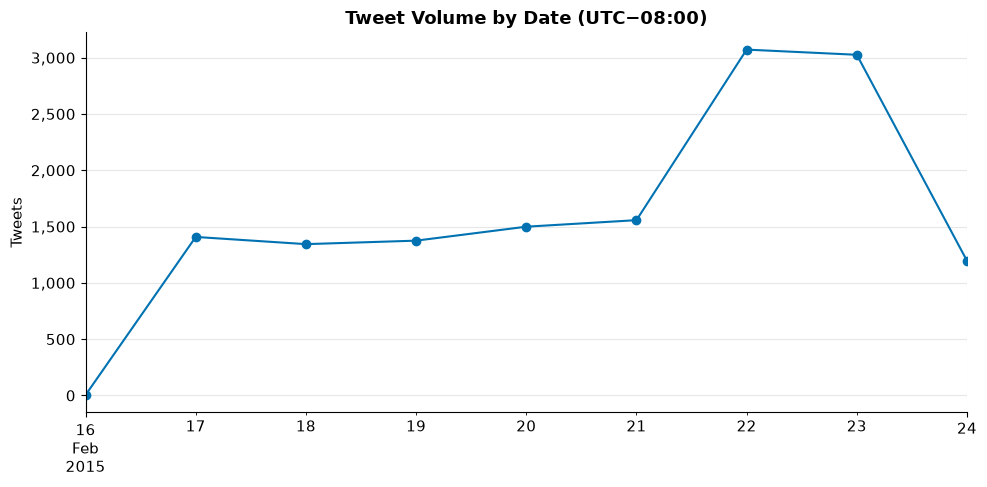

In [22]:
daily_volume = df.groupby("tweet_date").size()
display(daily_volume.to_frame("tweets"))

ax = daily_volume.plot(kind="line", marker="o", color=PRIMARY_COLOR)
ax.set_title("Tweet Volume by Date (UTC−08:00)")
ax.set_xlabel("")
ax.set_ylabel("Tweets")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()
plt.show()

### 17.1 Collection Coverage by Airline
Volume jumps sharply on 22–23 February. Before reading this as a real-world event, check whether every airline is covered on every day.

airline,American,JetBlue,Southwest,US Airways,United,Virgin America
tweet_date,,,,,,
2015-02-16,0,2,0,0,2,0
2015-02-17,0,263,384,311,396,54
2015-02-18,1,268,292,317,406,60
2015-02-19,1,282,317,279,426,70
2015-02-20,1,250,319,333,526,70
2015-02-21,1,243,370,360,506,77
2015-02-22,982,407,279,648,703,53
2015-02-23,1139,391,276,488,641,91
2015-02-24,479,112,183,177,216,29


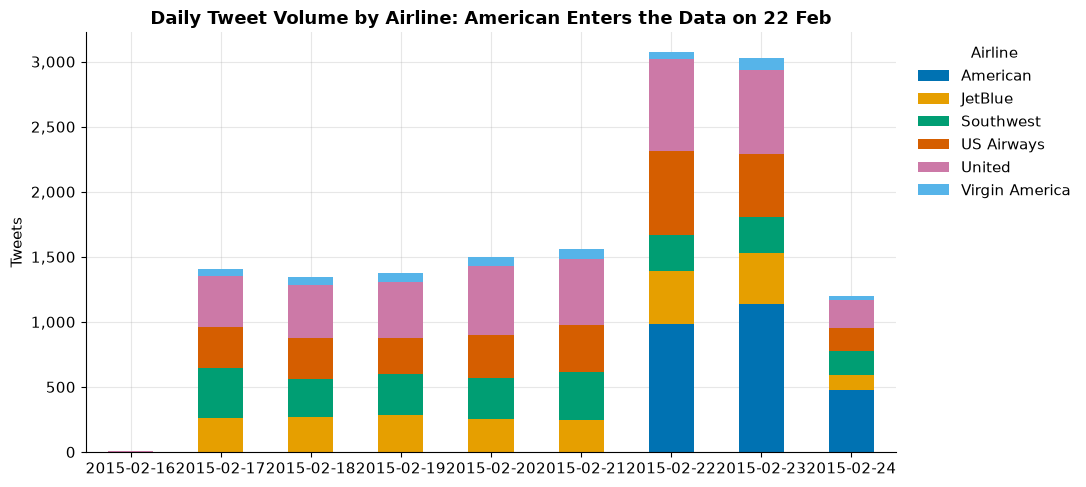

Share of American Airlines tweets dated 22-24 Feb: 99.85%


In [23]:
daily_airline_volume = pd.crosstab(df["tweet_date"].dt.date, df["airline"])
display(daily_airline_volume)

ax = daily_airline_volume.plot(kind="bar", stacked=True, figsize=(11, 5), color=CATEGORICAL_COLORS[:daily_airline_volume.shape[1]])
ax.set_title("Daily Tweet Volume by Airline: American Enters the Data on 22 Feb")
ax.set_xlabel("")
ax.set_ylabel("Tweets")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Airline", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
save_figure("daily_volume_by_airline.png")
plt.show()

american_share_late = (df.loc[df["airline"] == "American", "tweet_date"] >= "2015-02-22").mean() * 100
print(f"Share of American Airlines tweets dated 22-24 Feb: {american_share_late:.2f}%")

**Insight:** American Airlines is almost absent before 22 February (1 tweet or fewer per day) and then contributes 982–1,139 tweets per day. 99.85% of American's tweets fall on 22–24 February. The volume spike therefore reflects **how the dataset was collected**, not only customer behaviour, and daily totals should not be compared naively across dates.

## 18. Sentiment Over Time
**Objective:** track daily sentiment counts and the daily Negative share.

airline_sentiment,Positive,Neutral,Negative,negative_pct
tweet_date,,,,
2015-02-16,0,1,3,75.00
2015-02-17,273,297,838,59.52
2015-02-18,273,335,736,54.76
2015-02-19,295,329,751,54.62
2015-02-20,282,383,834,55.64
2015-02-21,230,278,1049,67.37
2015-02-22,349,462,2261,73.60
2015-02-23,433,676,1917,63.35
2015-02-24,197,306,693,57.94


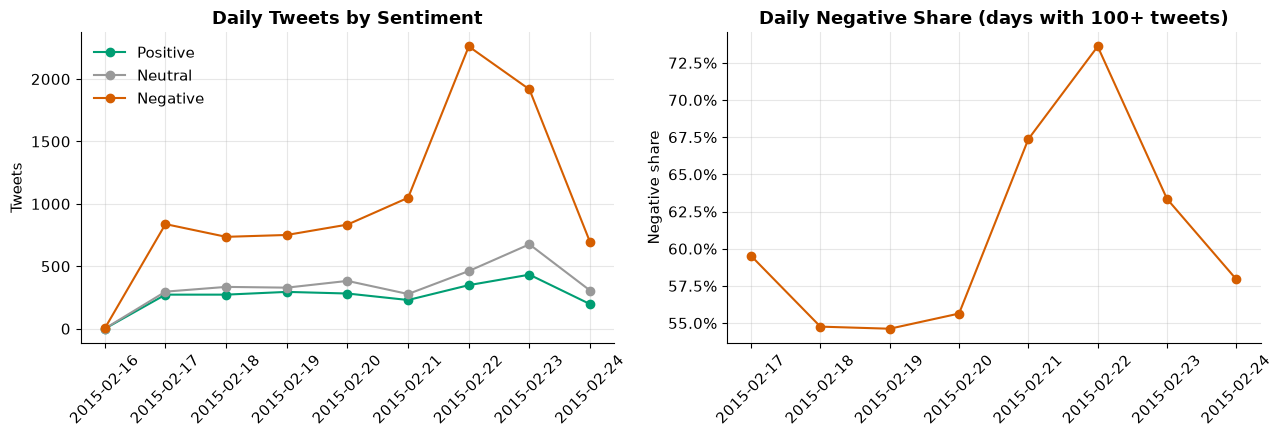

In [24]:
daily_sentiment = pd.crosstab(df["tweet_date"].dt.date, df["airline_sentiment"]).reindex(columns=SENTIMENT_ORDER)
daily_negative_pct = (daily_sentiment["Negative"] / daily_sentiment.sum(axis=1) * 100).round(2)
display(daily_sentiment.assign(negative_pct=daily_negative_pct))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for sentiment in SENTIMENT_ORDER:
    axes[0].plot(daily_sentiment.index, daily_sentiment[sentiment], marker="o",
                 color=SENTIMENT_COLORS[sentiment], label=sentiment)
axes[0].set_title("Daily Tweets by Sentiment")
axes[0].set_ylabel("Tweets")
axes[0].legend()

# The first date has only a handful of tweets, so the share chart starts on the first full day
full_days = daily_negative_pct[daily_sentiment.sum(axis=1) >= 100]
axes[1].plot(full_days.index, full_days.values, marker="o", color=SENTIMENT_COLORS["Negative"])
axes[1].set_title("Daily Negative Share (days with 100+ tweets)")
axes[1].set_ylabel("Negative share")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
save_figure("sentiment_over_time.png")
plt.show()

**Insight:** On full days, the Negative share ranges from about 55% (18–20 Feb) to a peak of 73.6% on 22 February. Counts peak on 22–23 February, partly because American Airlines enters the data then. The share, which is not affected by volume, also rises on 21–22 February.

## 19. Tweets by Month
**Objective:** summarise volume by calendar month.

In [25]:
monthly_volume = (
    df.groupby(["year", "month_number", "month"]).size()
    .rename("tweets").reset_index()
    .sort_values(["year", "month_number"])
)
monthly_volume

,year,month_number,month,tweets
0,2015,2,February,14481


**Insight:** All tweets fall in February 2015, so a monthly breakdown has only one value. `month` is kept in the dataset for completeness. No monthly or seasonal conclusion can be drawn.

## 20. Tweets by Weekday
**Objective:** compare volume by day of the week.

,tweets,distinct_dates
day_name,,
Monday,3030,2
Tuesday,2604,2
Wednesday,1344,1
Thursday,1375,1
Friday,1499,1
Saturday,1557,1
Sunday,3072,1


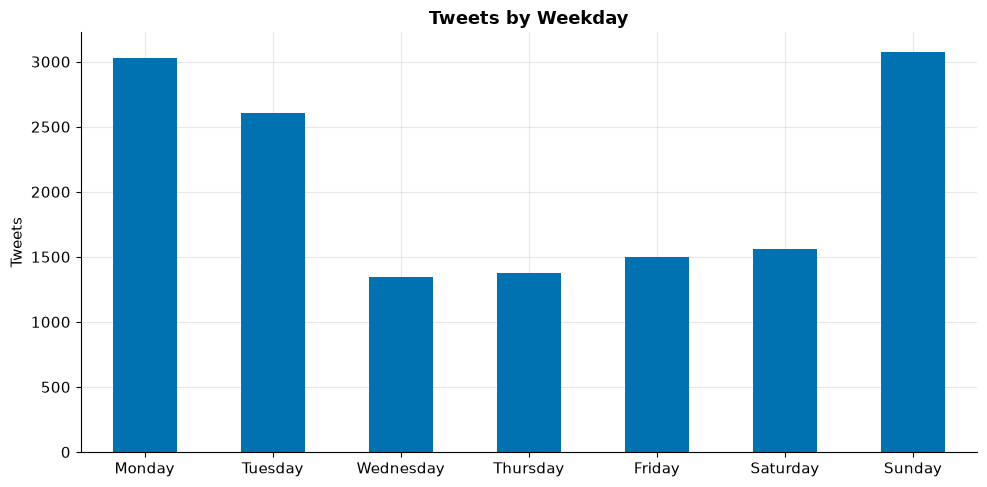

In [26]:
weekday_volume = df.groupby("day_name").size().reindex(WEEKDAY_ORDER)
dates_per_weekday = df.groupby("day_name")["tweet_date"].nunique().reindex(WEEKDAY_ORDER)
display(pd.DataFrame({"tweets": weekday_volume, "distinct_dates": dates_per_weekday}))

ax = weekday_volume.plot(kind="bar", color=PRIMARY_COLOR)
ax.set_title("Tweets by Weekday")
ax.set_xlabel("")
ax.set_ylabel("Tweets")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Insight:** Sunday (3,072) and Monday (3,030) have the most tweets. Each weekday appears on only one or two dates, and Sunday and Monday coincide with American Airlines entering the data. The weekday pattern is really a date pattern and should not be read as a recurring weekly effect.

## 21. Negative Tweets by Weekday
**Objective:** compare Negative volume and Negative share by weekday.

,negative_tweets,negative_pct
day_name,,
Monday,1920,63.37
Tuesday,1531,58.79
Wednesday,736,54.76
Thursday,751,54.62
Friday,834,55.64
Saturday,1049,67.37
Sunday,2261,73.60


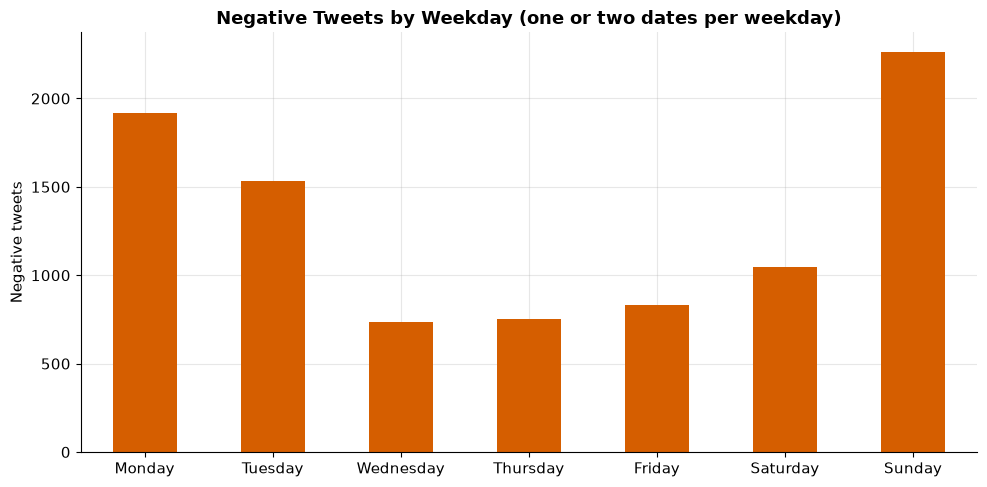

In [27]:
weekday_sentiment = pd.crosstab(df["day_name"], df["airline_sentiment"]).reindex(index=WEEKDAY_ORDER, columns=SENTIMENT_ORDER)
weekday_negative = pd.DataFrame({
    "negative_tweets": weekday_sentiment["Negative"],
    "negative_pct": (weekday_sentiment["Negative"] / weekday_sentiment.sum(axis=1) * 100).round(2),
})
display(weekday_negative)

ax = weekday_negative["negative_tweets"].plot(kind="bar", color=SENTIMENT_COLORS["Negative"])
ax.set_title("Negative Tweets by Weekday (one or two dates per weekday)")
ax.set_xlabel("")
ax.set_ylabel("Negative tweets")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Insight:** Sunday has both the most Negative tweets (2,261) and the highest Negative share (73.60%). With a single Sunday (22 Feb) in the data, this describes one specific day, not Sundays in general.

## 22. Tweets by Hour
**Objective:** see when during the day customers tweet, in the source's UTC−08:00 clock time.

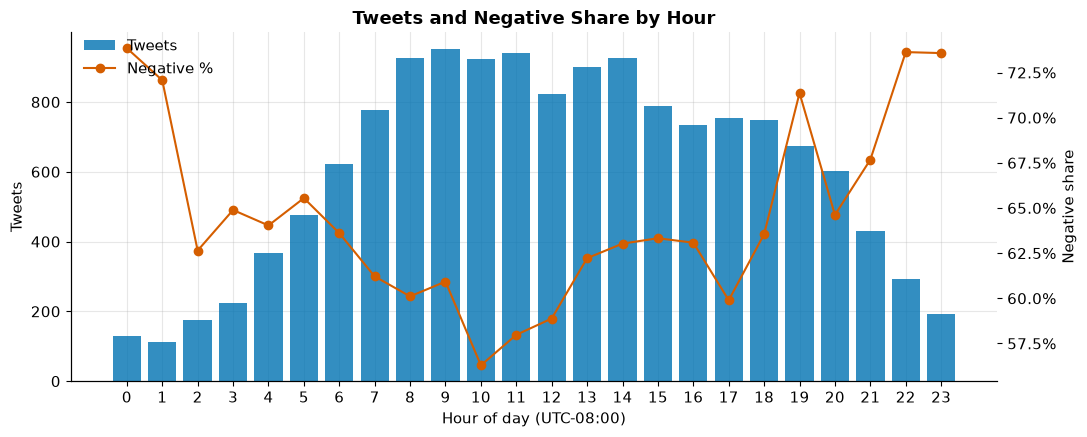

Busiest hour: 9:00 (952 tweets)
Negative share, 08:00-18:00: 60.74%
Negative share, 22:00-01:59: 73.42%


In [28]:
hourly = pd.crosstab(df["hour"], df["airline_sentiment"]).reindex(columns=SENTIMENT_ORDER)
hourly_negative_pct = hourly["Negative"] / hourly.sum(axis=1) * 100

fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(hourly.index, hourly.sum(axis=1), color=PRIMARY_COLOR, alpha=0.8, label="Tweets")
ax1.set_xlabel("Hour of day (UTC-08:00)")
ax1.set_ylabel("Tweets")
ax1.set_xticks(range(0, 24))

ax2 = ax1.twinx()
ax2.plot(hourly.index, hourly_negative_pct, color=SENTIMENT_COLORS["Negative"], marker="o", label="Negative %")
ax2.set_ylabel("Negative share")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.grid(False)
ax1.set_title("Tweets and Negative Share by Hour")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.93))
plt.tight_layout()
plt.show()

print(f"Busiest hour: {hourly.sum(axis=1).idxmax()}:00 ({hourly.sum(axis=1).max():,} tweets)")
print(f"Negative share, 08:00-18:00: {hourly.loc[8:18, 'Negative'].sum() / hourly.loc[8:18].values.sum() * 100:.2f}%")
print(f"Negative share, 22:00-01:59: {hourly.loc[[22, 23, 0, 1], 'Negative'].sum() / hourly.loc[[22, 23, 0, 1]].values.sum() * 100:.2f}%")

**Insight:** Volume is highest between 08:00 and 14:00 and lowest overnight. Late-night tweets (22:00–01:59) are more negative (73.4%) than daytime tweets (60.7%, 08:00–18:00). A plausible reading is that late-night tweets come from disrupted travellers, but the data cannot confirm the reason.

## 23. Average Sentiment Score by Airline
**Objective:** compare the mean of `sentiment_score` (Positive = 1, Neutral = 0, Negative = −1).

,average_sentiment_score
airline,
US Airways,-0.6845
American,-0.5991
United,-0.5602
Southwest,-0.2545
JetBlue,-0.1849
Virgin America,-0.0575


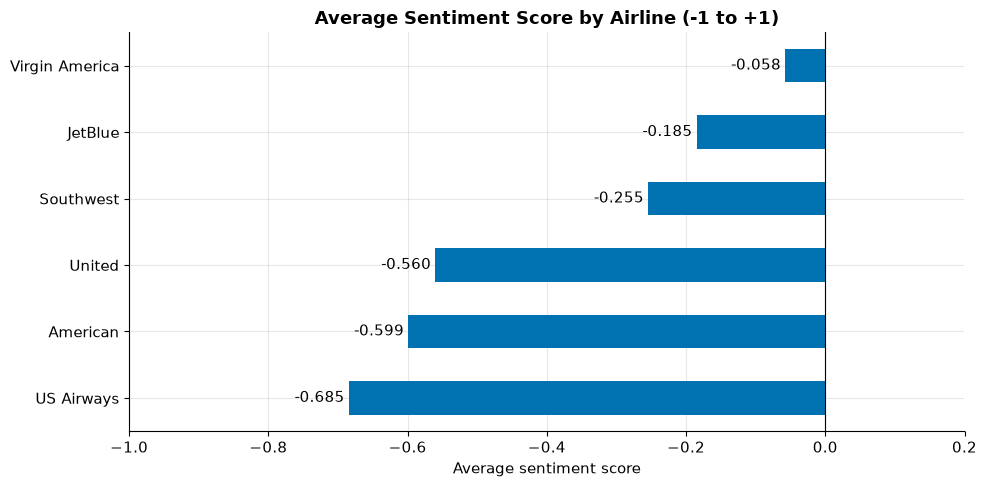

In [29]:
average_sentiment_score = df.groupby("airline")["sentiment_score"].mean().sort_values()
display(average_sentiment_score.round(4).to_frame("average_sentiment_score"))

ax = average_sentiment_score.plot(kind="barh", color=PRIMARY_COLOR)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-1, 0.2)
ax.set_title("Average Sentiment Score by Airline (-1 to +1)")
ax.set_xlabel("Average sentiment score")
ax.set_ylabel("")
ax.bar_label(ax.containers[0], fmt="{:.3f}", padding=3)
plt.tight_layout()
plt.show()

**Insight:** The ranking is identical to the Net Sentiment Score. Mathematically, the average score equals Net Sentiment Score ÷ 100 (Virgin America −0.058, US Airways −0.685). The two metrics are interchangeable, so the project uses Net Sentiment Score as its headline KPI.

## Key EDA Findings

The generated summary below pulls every figure from the variables computed above.

In [30]:
top_reason = reason_counts.index[0]
findings = [
    f"Negative tweets dominate: {sentiment_pct['Negative']:.2f}% Negative vs {sentiment_pct['Positive']:.2f}% Positive "
    f"(overall Net Sentiment Score {overall_net_score:.2f}).",
    f"{airline_volume.index[0]} is the most-discussed airline ({airline_volume.iloc[0]:,} tweets); "
    f"{airline_volume.index[-1]} the least ({airline_volume.iloc[-1]:,}).",
    f"Best Net Sentiment Score: {net_sentiment.index[-1]} ({net_sentiment.iloc[-1]:.2f}); "
    f"worst: {net_sentiment.index[0]} ({net_sentiment.iloc[0]:.2f}).",
    f"Highest Positive %: {positive_ranking.index[0]} ({positive_ranking.iloc[0]:.2f}%); "
    f"highest Negative %: {negative_ranking.index[0]} ({negative_ranking.iloc[0]:.2f}%).",
    f"Top complaint: {top_reason} ({reason_counts.iloc[0]:,} tweets, {reason_pct.iloc[0]:.2f}% of Negative tweets); "
    f"it is the #1 complaint for {(top_complaint_per_airline['top_complaint'] == top_reason).sum()} of 6 airlines.",
    f"Retweets are sparse ({zero_share:.2f}% of tweets have none); Negative tweets have the highest average "
    f"({retweets_by_sentiment.loc['Negative', 'average_retweets']:.3f}).",
    f"American Airlines appears almost only on 22-24 Feb ({american_share_late:.2f}% of its tweets), "
    f"so date and weekday spikes partly reflect data collection.",
]
for number, finding in enumerate(findings, start=1):
    print(f"{number}. {finding}")

1. Negative tweets dominate: 62.72% Negative vs 16.10% Positive (overall Net Sentiment Score -46.61).
2. United is the most-discussed airline (3,822 tweets); Virgin America the least (504).
3. Best Net Sentiment Score: Virgin America (-5.75); worst: US Airways (-68.45).
4. Highest Positive %: Virgin America (30.16%); highest Negative %: US Airways (77.69%).
5. Top complaint: Customer Service Issue (2,883 tweets, 31.74% of Negative tweets); it is the #1 complaint for 5 of 6 airlines.
6. Retweets are sparse (94.73% of tweets have none); Negative tweets have the highest average (0.094).
7. American Airlines appears almost only on 22-24 Feb (99.85% of its tweets), so date and weekday spikes partly reflect data collection.


**Summary**

1. **Sentiment is mostly negative.** About 63% of tweets are Negative, so comparisons should focus on relative differences between airlines.
2. **Two groups of airlines.** Virgin America, JetBlue and Southwest have Negative shares below 50%. US Airways, American and United have Negative shares of 69–78%.
3. **Customer service is the main complaint theme.** It leads the complaint mix for 5 of 6 airlines. JetBlue's top complaint is Late Flight.
4. **Complaints are amplified slightly more.** Negative tweets are about twice as likely to be retweeted, but retweets are rare overall and driven by a few outliers.
5. **Time patterns need caution.** The dataset covers about eight days and American Airlines enters only on 22 February. Date and weekday results describe this sample only and do not support forecasting or seasonality claims.
6. **Data-quality notes.** The source labelled JetBlue tweets as "Delta"; this was corrected in notebook 02. A single viral JetBlue post inflates JetBlue's average retweets.